# 12 Privacy-preserving cross-bank learning
Five simulated banks; each sees only payments it originates or receives, so mule networks spanning banks are fragmented. Horizontal FL (same features, different customers) is simulated in one process.

**What this is not:** federated learning alone does not guarantee privacy (updates can leak). Secure aggregation here is a simulation of pairwise masking; differential privacy is client-level with only five clients, so the formal guarantee is weak and reported for the trade-off only.

In [1]:
import sys, pathlib, json, warnings; warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import Image, display
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
def table(name):
    p = ROOT / 'reports' / 'tables' / name
    return pd.read_csv(p) if p.exists() else None

In [2]:
import torch
from presage.federated.fl import secure_aggregate, rdp_epsilon
ups = [torch.randn(8) for _ in range(5)]; print('masks cancel:', torch.allclose(secure_aggregate(ups), torch.stack(ups).sum(0), atol=1e-3))
print({s: round(rdp_epsilon(s, 15), 1) for s in (0.5, 1.0, 2.0)}, '<- epsilon (delta=1e-5) after 15 rounds by noise multiplier')

masks cancel: True
{0.5: 67.2, 1.0: 26.1, 2.0: 11.2} <- epsilon (delta=1e-5) after 15 rounds by noise multiplier


In [3]:
f = table('federated.csv'); f.round(3) if f is not None else 'run scripts/run_federated.py'

,method,pr_auc,recall,precision,f1,fpr,crossbank_pr_auc,crossbank_recall,bytes_up,eps
0,local_only,0.713,0.723,0.548,0.623,0.003,0.713,0.735,0.0,NaN
1,fedavg,0.811,0.748,0.695,0.720,0.002,0.806,0.751,5820600.0,NaN
2,fedavg_personalised,0.816,0.700,0.841,0.764,0.001,0.814,0.699,5820600.0,NaN
3,fedprox(mu=0.05),0.739,0.713,0.646,0.678,0.002,0.727,0.707,5820600.0,NaN
4,fedavg+secure_agg(sim),0.821,0.761,0.715,0.738,0.001,0.814,0.759,5820600.0,NaN
5,fedavg+DP(sigma=0.5),0.012,0.329,0.017,0.032,0.095,0.013,0.382,5820600.0,67.169
6,fedavg+DP(sigma=1.0),0.009,0.058,0.074,0.065,0.004,0.010,0.068,5820600.0,26.085
7,fedavg+DP(sigma=2.0),0.011,0.013,0.444,0.025,0.000,0.012,0.016,5820600.0,11.168
8,centralised_pooled(local feats),0.821,0.648,0.878,0.746,0.000,0.815,0.659,NaN,NaN
9,centralised_full_visibility(oracle),0.929,0.868,0.903,0.885,0.000,0.934,0.867,NaN,NaN


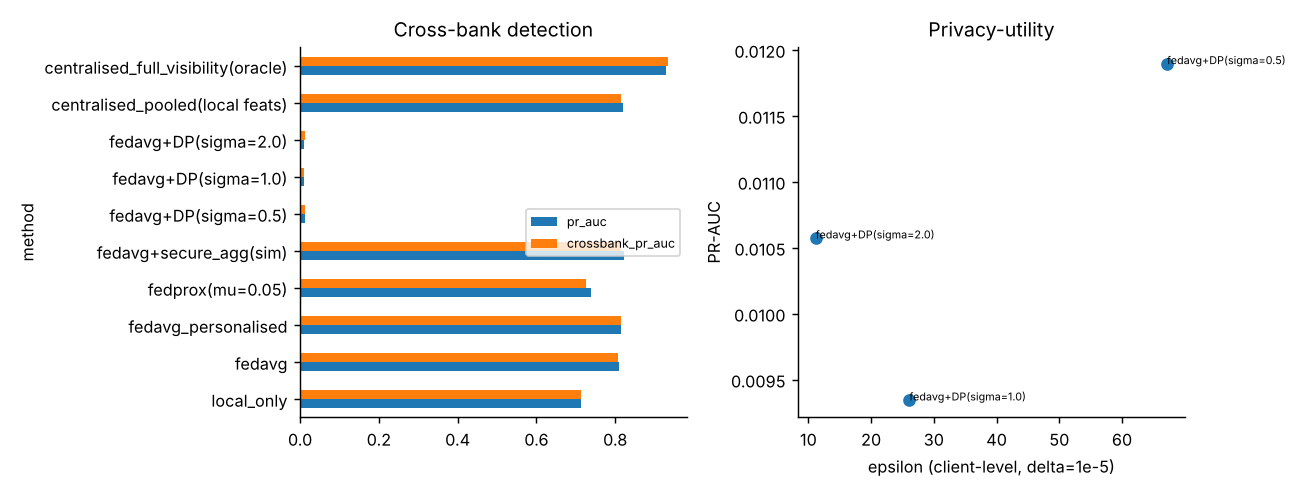

In [4]:
p = ROOT/'reports'/'figures'/'fig_federated.png'; display(Image(str(p))) if p.exists() else None

**Vertical FL and federated graph learning.** Here the parties hold *different rows of the same schema* (horizontal). Real inter-bank collaboration on graphs is closer to vertical/federated *graph* learning where cross-bank edges cannot be pooled; established approaches (e.g. federated GNN training with neighbour-feature exchange, or privacy-preserving entity linkage) are future work and not claimed here. Our `centralised_full_visibility` row is an oracle showing how much the unseen cross-bank edges are worth.